# 03 — Forecasting hotel nights 1-6 months ahead, with and without the franc

## Summary (Sprint 3, part A)

**The model beats "same month last year" overall, but the franc adds no measurable out-of-sample gain.** Over 57 series, 6 horizons and 43 post-covid target months, WAPE is 8.7% for the seasonal naive, 8.3% for the model without FX and 8.2% with FX (FX gain +0.16 points). The largest FX gain is for **Swiss guests (+0.31 points, better in 6/6 horizons), whose FX feature is always 0**: gains of this size come from re-fitting the global model, not from information in the exchange rate.

**By origin market** (WAPE %, all horizons; FX gain = without minus with FX, points):

| Market | FX feature | Naive | Without FX | With FX | FX gain | FX better in |
|---|---|---|---|---|---|---|
| Switzerland | none (0) | 6.2 | 6.6 | 6.3 | +0.31 | 6/6 |
| Germany | EUR | 9.6 | 9.9 | 9.9 | +0.03 | 2/6 |
| France | EUR | 8.0 | 8.1 | 8.1 | +0.02 | 4/6 |
| Italy | EUR | 11.7 | 12.0 | 12.0 | -0.01 | 3/6 |
| United Kingdom | GBP | 13.7 | 12.0 | 12.3 | -0.37 | 1/6 |
| United States | USD | 13.7 | 9.4 | 9.4 | -0.07 | 3/6 |
| China | CNY | 34.2 | 27.5 | 27.6 | -0.14 | 3/6 |
| Resort totals | EUR | 8.0 | 8.4 | 8.2 | +0.18 | 4/6 |

- **Germany**, the market most linked to EUR/CHF in notebook 02, gains +0.03 points (2/6 horizons); for the **United Kingdom** FX makes WAPE worse by 0.37 points.
- **Where the model helps:** the United States (13.7% -> 9.4%), China (34.2% -> 27.5%) and the United Kingdom (13.7% -> 12.0%). For Swiss guests, Germany, France, Italy and the resort totals, the model without FX is slightly **worse** than the seasonal naive: "same month last year" is hard to beat for stable European demand.
- **By horizon:** the model is most useful at h=1 (WAPE 7.4% vs 8.7% naive); at h=6 the model without FX is worse than the naive (9.0% vs 8.7%) and FX brings it to 8.6%.
- **Peak season** (each series' 3 highest months): naive 8.5%, without FX 8.4%, with FX 8.1%.
- **Per series:** FX lowers WAPE in 30 of 57 series; the model without FX beats the naive in only 24 of 57 series (its overall advantage comes from the larger, more volatile series).

Results use scikit-learn's `HistGradientBoostingRegressor`, because LightGBM could not be installed on this machine. Every number in this summary is checked against the results by the last code cell ("Summary check").

## Set-up

**Product.** Forecast monthly hotel overnight stays by canton, origin market and resort type six months ahead (seasonal pricing, seasonal staffing), and measure how much the Swiss franc moves that forecast.

**Series (57).** 7 cantons x 7 origin markets (49) + the total of each of the 8 paired resorts (4 luxury, 4 mid-range; total = sum of the 7 tracked markets, a suppressed small market counts as 0).

**Models** (all evaluated identically):
1. **Seasonal naive**: same month last year.
2. **Model without FX**: one global gradient-boosting model per horizon h = 1..6 (direct strategy). Target = seasonal log change `log1p(y[t+h]) - log1p(y[t+h-12])`, i.e. a correction to the seasonal-naive forecast. Features known at the origin t: log nights at t, t-1, t-2, same month 1 and 2 years before the target, 3- and 12-month means ending at t, YoY change at t, target month, level, canton/resort, origin market, covid indicators (target month, its base month, origin) and a post-covid indicator (calendar rules: covid = Mar 2020 - Dec 2021, post-covid from Jan 2022). No regime detection, so nothing estimated from data can leak.
3. **Model with FX**: the same + ONE symmetric feature, the YoY log change of the market's own currency vs CHF at the origin month (= lag h of the target); EUR for resort totals, 0 for Swiss guests.

**Backend.** Results use scikit-learn's `HistGradientBoostingRegressor`, because LightGBM could not be installed on this machine (no `libomp` for macOS 14 on Intel). `src/forecast.py` takes `backend="lightgbm"` if it can be imported. Hyperparameters are fixed and modest (`forecast.PARAMS`); nothing is tuned on the test period.

**Validation.** Rolling origin, expanding window: the same 43 target months (Jan 2023 - Jul 2026) for every horizon, origin = target - h, training only on rows whose target month is <= the origin. Covid months stay in training with indicators and are never evaluated.

**Metrics.** Main: **WAPE** = sum of absolute errors / sum of actuals (robust to small, near-zero months). MAPE per series is secondary. Peak-season months = each series' 3 highest months by average share of annual nights, 2013-2019.

Language is descriptive: the FX feature "improves" or "does not improve" the forecast; nothing here measures causal effects.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import (GREY, INK, INK_SOFT, ORIGIN_COLORS, SLOTS, SOURCE_BFS_SNB, add_source, connect,
                    save, set_style, shade_covid, year_axis)
import forecast as fc

BACKEND = "sklearn"
set_style()
pd.set_option("display.precision", 2)
con = connect()

panel = fc.load_panel(con)
fx_yoy = fc.load_fx_yoy(con)
peak = fc.peak_months(panel)
print(panel.groupby("level")["series_id"].nunique().to_dict(),
      f"| {panel['date'].min():%Y-%m} -> {panel['date'].max():%Y-%m}",
      f"| resort months with a suppressed market: {int(panel['partial'].sum())}")
print("Backend:", BACKEND, "| hyperparameters:", fc.PARAMS)

{'canton': 49, 'resort': 8} | 2005-01 -> 2026-08 | resort months with a suppressed market: 51
Backend: sklearn | hyperparameters: {'n_trees': 400, 'learning_rate': 0.03, 'leaves': 15, 'min_leaf': 20, 'col_sample': 0.8, 'row_sample': 0.8, 'seed': 42}


## No look-ahead check

Every value after the origin (nights and FX) is scrambled; the forecasts made at that origin must not change.

In [2]:
for h, origin in [(1, "2023-06-01"), (3, "2024-06-01"), (6, "2025-12-01")]:
    diff = fc.check_no_lookahead(panel, fx_yoy, h, pd.Timestamp(origin), backend=BACKEND)
    print(f"h={h}, origin {origin}: max change in forecasts = {diff}")

h=1, origin 2023-06-01: max change in forecasts = 0.0


h=3, origin 2024-06-01: max change in forecasts = 0.0


h=6, origin 2025-12-01: max change in forecasts = 0.0


## Backtest

6 horizons x 43 target months x 2 models = 516 model fits (several minutes).

In [3]:
t0 = time.time()
res = fc.backtest(panel, fx_yoy, backend=BACKEND)
res["month"] = res["target_date"].dt.month
res = res.merge(peak, on=["series_id", "month"], how="left").fillna({"peak": False})
res["market"] = np.where(res["level"] == "resort", "Resort totals", res["origin"])
print(f"{len(res):,} forecasts in {time.time() - t0:.0f}s | target months "
      f"{res['target_date'].min():%Y-%m} -> {res['target_date'].max():%Y-%m} | "
      f"{res['target_date'].nunique()} months, {res['series_id'].nunique()} series, "
      f"horizons {sorted(int(h) for h in res['h'].unique())}")
assert res.groupby("series_id")["peak"].any().all(), "every series needs peak-season months in the test"
print(f"Peak-season forecasts: {int(res['peak'].sum()):,} of {len(res):,}")

14,706 forecasts in 540s | target months 2023-01 -> 2026-07 | 43 months, 57 series, horizons [1, 2, 3, 4, 5, 6]
Peak-season forecasts: 3,678 of 14,706


## 1. Overall and by horizon

In [4]:
overall = pd.concat([fc.wape_table(res, []).assign(months="all"),
                     fc.wape_table(res[res["peak"]], []).assign(months="peak season")]).set_index("months")
display(overall[["naive", "gb_no_fx", "gb_fx", "fx_gain", "n"]])
by_h = pd.concat([fc.wape_table(res, ["h"]).assign(months="all"),
                  fc.wape_table(res[res["peak"]], ["h"]).assign(months="peak season")])
display(by_h.pivot(index="h", columns="months", values=["naive", "gb_no_fx", "gb_fx"]))
o = overall.loc["all"]; p = overall.loc["peak season"]
print(f"All months, h=1-6: WAPE naive {o.naive:.1f}%, without FX {o.gb_no_fx:.1f}%, with FX {o.gb_fx:.1f}% "
      f"(FX gain {o.fx_gain:+.2f} pts).")
print(f"Peak season:       WAPE naive {p.naive:.1f}%, without FX {p.gb_no_fx:.1f}%, with FX {p.gb_fx:.1f}% "
      f"(FX gain {p.fx_gain:+.2f} pts).")
h6 = by_h[(by_h["months"] == "all") & (by_h["h"] == 6)].iloc[0]
print(f"h=6, all months: naive {h6.naive:.1f}%, without FX {h6.gb_no_fx:.1f}%, with FX {h6.gb_fx:.1f}%.")

,naive,gb_no_fx,gb_fx,fx_gain,n
months,,,,,
all,8.74,8.33,8.17,0.16,14706
peak season,8.47,8.39,8.12,0.27,3678


naive             gb_no_fx             gb_fx            
months   all peak season      all peak season   all peak season
h                                                              
1       8.74        8.47     7.44        7.56  7.44        7.42
2       8.74        8.47     8.28        8.50  7.97        8.08
3       8.74        8.47     8.27        8.14  8.30        8.14
4       8.74        8.47     8.33        8.04  8.24        8.01
5       8.74        8.47     8.67        8.63  8.47        8.46
6       8.74        8.47     9.01        9.46  8.61        8.60

All months, h=1-6: WAPE naive 8.7%, without FX 8.3%, with FX 8.2% (FX gain +0.16 pts).
Peak season:       WAPE naive 8.5%, without FX 8.4%, with FX 8.1% (FX gain +0.27 pts).
h=6, all months: naive 8.7%, without FX 9.0%, with FX 8.6%.


### Chart 10 — WAPE by horizon

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/10_wape_by_horizon.png')

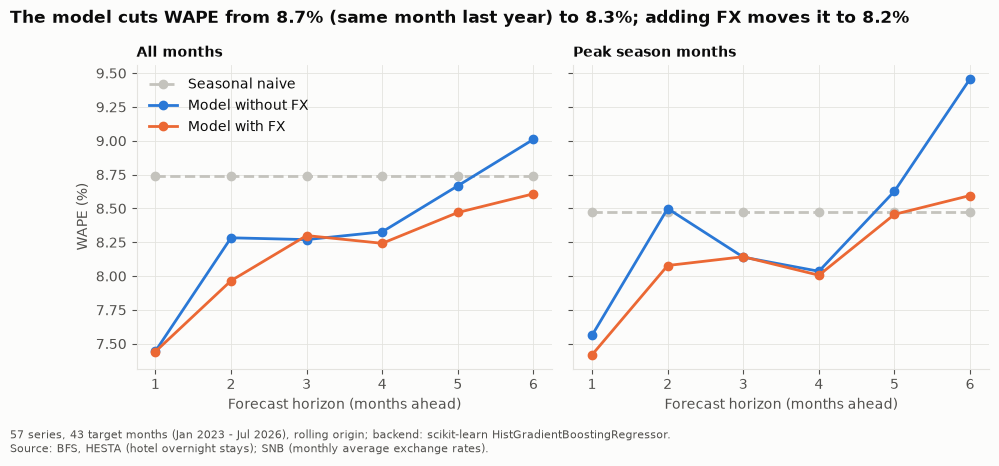

In [5]:
STYLE = {"naive": dict(color=GREY, ls="--"), "gb_no_fx": dict(color=SLOTS[0]), "gb_fx": dict(color=SLOTS[1])}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, months in zip(axes, ["all", "peak season"]):
    t = by_h[by_h["months"] == months]
    for col, label in fc.MODELS.items():
        ax.plot(t["h"], t[col], marker="o", label=label, **STYLE[col])
    ax.set_title(f"{months.capitalize()} months", loc="left", fontsize=10)
    ax.set_xlabel("Forecast horizon (months ahead)")
    ax.set_xticks(list(fc.HORIZONS))
axes[0].set_ylabel("WAPE (%)")
axes[0].legend(loc="upper left")
fig.suptitle(f"The model cuts WAPE from {o.naive:.1f}% (same month last year) to {o.gb_no_fx:.1f}%; "
             f"adding FX moves it to {o.gb_fx:.1f}%", x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", f"57 series, 43 target months (Jan 2023 - Jul 2026), rolling origin; "
           f"backend: scikit-learn HistGradientBoostingRegressor.")
fig.subplots_adjust(bottom=0.2, top=0.86, wspace=0.05)
save(fig, "10_wape_by_horizon")

## 2. By origin market — where the franc helps and where it does not

In [6]:
MARKET_ORDER = ["Switzerland", "Germany", "France", "Italy", "United Kingdom", "United States", "China",
                "Resort totals"]
by_market = fc.wape_table(res, ["market"]).set_index("market").loc[MARKET_ORDER]
gain_h = fc.wape_table(res, ["market", "h"])
by_market["fx_helps_in_h"] = gain_h.groupby("market")["fx_gain"].apply(lambda g: int((g > 0).sum()))
by_market["fx_currency"] = ["none (CHF)", "EUR", "EUR", "EUR", "GBP", "USD", "CNY", "EUR"]
display(by_market[["fx_currency", "naive", "gb_no_fx", "gb_fx", "fx_gain", "fx_helps_in_h", "n"]])
for m, r in by_market.iterrows():
    print(f"{m:<15} WAPE naive {r.naive:5.1f}% | without FX {r.gb_no_fx:5.1f}% | with FX {r.gb_fx:5.1f}% | "
          f"FX gain {r.fx_gain:+.2f} pts, better in {r.fx_helps_in_h}/6 horizons")

,fx_currency,naive,gb_no_fx,gb_fx,fx_gain,fx_helps_in_h,n
market,,,,,,,
Switzerland,none (CHF),6.21,6.62,6.31,0.31,6,1806
Germany,EUR,9.62,9.92,9.89,0.03,2,1806
France,EUR,8.04,8.11,8.09,0.02,4,1806
Italy,EUR,11.71,11.97,11.98,-0.01,3,1806
United Kingdom,GBP,13.65,11.97,12.34,-0.37,1,1806
United States,USD,13.65,9.36,9.44,-0.07,3,1806
China,CNY,34.24,27.50,27.64,-0.14,3,1806
Resort totals,EUR,8.00,8.38,8.20,0.18,4,2064


Switzerland     WAPE naive   6.2% | without FX   6.6% | with FX   6.3% | FX gain +0.31 pts, better in 6/6 horizons
Germany         WAPE naive   9.6% | without FX   9.9% | with FX   9.9% | FX gain +0.03 pts, better in 2/6 horizons
France          WAPE naive   8.0% | without FX   8.1% | with FX   8.1% | FX gain +0.02 pts, better in 4/6 horizons
Italy           WAPE naive  11.7% | without FX  12.0% | with FX  12.0% | FX gain -0.01 pts, better in 3/6 horizons
United Kingdom  WAPE naive  13.7% | without FX  12.0% | with FX  12.3% | FX gain -0.37 pts, better in 1/6 horizons
United States   WAPE naive  13.7% | without FX   9.4% | with FX   9.4% | FX gain -0.07 pts, better in 3/6 horizons
China           WAPE naive  34.2% | without FX  27.5% | with FX  27.6% | FX gain -0.14 pts, better in 3/6 horizons
Resort totals   WAPE naive   8.0% | without FX   8.4% | with FX   8.2% | FX gain +0.18 pts, better in 4/6 horizons


## 3. By canton and resort

In [7]:
by_geo = fc.wape_table(res, ["level", "geo"]).sort_values(["level", "fx_gain"], ascending=[True, False])
by_geo["resort_type"] = by_geo["geo"].map(fc.RESORTS)
display(by_geo.set_index(["level", "geo"])[["resort_type", "naive", "gb_no_fx", "gb_fx", "fx_gain"]])
by_type = fc.wape_table(res[res["level"] == "resort"], ["resort_type"]).set_index("resort_type")
display(by_type[["naive", "gb_no_fx", "gb_fx", "fx_gain"]])

resort_type  naive  gb_no_fx  gb_fx  fx_gain
level  geo                                                    
canton Graubünden         NaN   8.31      9.21   8.69     0.52
       Valais             NaN   7.73      7.65   7.41     0.24
       Lucerne            NaN  10.75      9.54   9.43     0.11
       Vaud               NaN   7.70      7.55   7.49     0.05
       Bern               NaN   8.39      7.86   7.82     0.04
       Zurich             NaN   9.38      7.92   7.89     0.03
       Geneva             NaN  11.01      9.13   9.21    -0.07
resort Saanen          luxury   6.42      7.09   6.73     0.36
       Scuol        mid-range   8.87      9.93   9.59     0.34
       St. Moritz      luxury   8.41      8.65   8.36     0.28
       Lenk         mid-range  11.67     11.84  11.62     0.22
       Klosters        luxury  13.28     13.60  13.41     0.19
       Saas-Grund   mid-range  31.75     32.47  32.36     0.11
       Zermatt         luxury   5.54      5.79   5.72     0.06
       Tujetsch     mid-range  22.91     23.93  24.03    -0.10

,naive,gb_no_fx,gb_fx,fx_gain
resort_type,,,,
luxury,6.86,7.16,6.99,0.17
mid-range,13.57,14.35,14.11,0.24


## 4. Per series (57)

FX gain = WAPE without FX minus WAPE with FX (points; positive = FX helps). "Better in k/6" counts the horizons where FX lowers WAPE. With 43 target months per horizon, small gains can be noise. MAPE is shown as a secondary metric.

In [8]:
per_series = fc.wape_table(res, ["series_id", "level", "market"])
k = fc.wape_table(res, ["series_id", "h"]).groupby("series_id")["fx_gain"].apply(lambda g: int((g > 0).sum()))
per_series["fx_helps_in_h"] = per_series["series_id"].map(k)
mape = res.groupby("series_id").apply(lambda g: pd.Series({f"mape_{c}": fc.mape(g["actual"], g[c])
                                                           for c in ["naive", "gb_no_fx", "gb_fx"]}),
                                      include_groups=False)
per_series = per_series.merge(mape, left_on="series_id", right_index=True).sort_values("fx_gain", ascending=False)
assert len(per_series) == 57
display(per_series.set_index("series_id")[["naive", "gb_no_fx", "gb_fx", "fx_gain", "fx_helps_in_h",
                                           "mape_naive", "mape_gb_no_fx", "mape_gb_fx"]])
n_gain = int((per_series["fx_gain"] > 0).sum())
model_beats_naive = int((per_series["gb_no_fx"] < per_series["naive"]).sum())
print(f"FX lowers WAPE in {n_gain} of 57 series; the model without FX beats the seasonal naive in "
      f"{model_beats_naive} of 57 series.")
print("Largest FX gains:", ", ".join(f"{r.series_id} ({r.fx_gain:+.2f})" for r in per_series.head(5).itertuples()))
print("Largest FX losses:", ", ".join(f"{r.series_id} ({r.fx_gain:+.2f})" for r in per_series.tail(5).itertuples()))

,naive,gb_no_fx,gb_fx,fx_gain,fx_helps_in_h,mape_naive,mape_gb_no_fx,mape_gb_fx
series_id,,,,,,,,
Graubünden | Switzerland,6.71,8.03,7.34,6.89e-01,6,7.61,8.42,7.74
Valais | United States,14.87,9.61,8.96,6.53e-01,2,16.01,10.49,9.78
Graubünden | United Kingdom,9.84,9.98,9.38,6.00e-01,5,11.52,11.06,10.60
Valais | United Kingdom,9.52,9.46,8.97,4.97e-01,3,11.84,11.88,11.85
Graubünden | France,18.62,19.02,18.59,4.30e-01,4,16.44,17.85,17.75
Saanen (resort),6.42,7.09,6.73,3.62e-01,5,7.96,8.45,7.98
Lucerne | Switzerland,5.88,6.68,6.33,3.47e-01,5,6.03,6.84,6.50
Scuol (resort),8.87,9.93,9.59,3.44e-01,4,12.20,12.96,12.45
Lucerne | China,42.02,37.79,37.46,3.39e-01,4,50.18,43.04,42.54


FX lowers WAPE in 30 of 57 series; the model without FX beats the seasonal naive in 24 of 57 series.
Largest FX gains: Graubünden | Switzerland (+0.69), Valais | United States (+0.65), Graubünden | United Kingdom (+0.60), Valais | United Kingdom (+0.50), Graubünden | France (+0.43)
Largest FX losses: Vaud | United States (-0.66), Graubünden | China (-0.85), Graubünden | United States (-0.89), Zurich | United Kingdom (-1.26), Lucerne | United Kingdom (-1.29)


### Chart 11 — Actual vs forecast, 6 months ahead, three example series

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/11_actual_vs_forecast_h6.png')

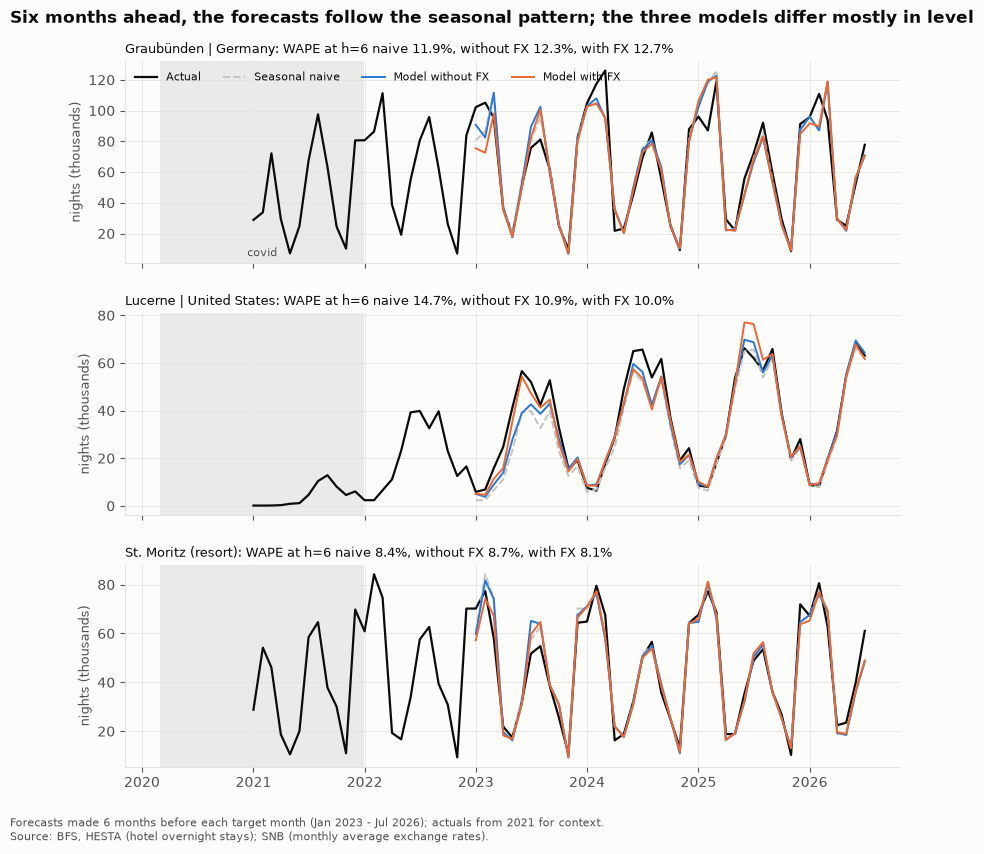

In [9]:
EXAMPLES = ["Graubünden | Germany", "Lucerne | United States", "St. Moritz (resort)"]
fig, axes = plt.subplots(3, 1, figsize=(10, 8.6), sharex=True)
for ax, sid in zip(axes, EXAMPLES):
    hist = panel[(panel["series_id"] == sid) & (panel["date"] >= "2021-01-01") & (panel["date"] <= fc.TEST_END)]
    f6 = res[(res["series_id"] == sid) & (res["h"] == 6)].sort_values("target_date")
    shade_covid(ax, label=ax is axes[0])
    ax.plot(hist["date"], hist["nights"] / 1e3, color=INK, lw=1.6, label="Actual")
    for col, label in fc.MODELS.items():
        ax.plot(f6["target_date"], f6[col] / 1e3, lw=1.4, label=label, **STYLE[col])
    w = {c: fc.wape(f6["actual"], f6[c]) for c in fc.MODELS}
    ax.set_title(f"{sid}: WAPE at h=6 naive {w['naive']:.1f}%, without FX {w['gb_no_fx']:.1f}%, "
                 f"with FX {w['gb_fx']:.1f}%", loc="left", fontsize=9, fontweight="normal")
    ax.set_ylabel("nights (thousands)", fontsize=9)
axes[0].legend(ncol=4, loc="upper left", fontsize=8)
year_axis(axes[-1], step=1)
fig.suptitle("Six months ahead, the forecasts follow the seasonal pattern; the three models differ "
             "mostly in level", x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Forecasts made 6 months before each target month (Jan 2023 - Jul 2026); "
           "actuals from 2021 for context.")
fig.subplots_adjust(bottom=0.1, top=0.92, hspace=0.25)
save(fig, "11_actual_vs_forecast_h6")

### Chart 12 — FX gain per series

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/12_fx_gain_by_series.png')

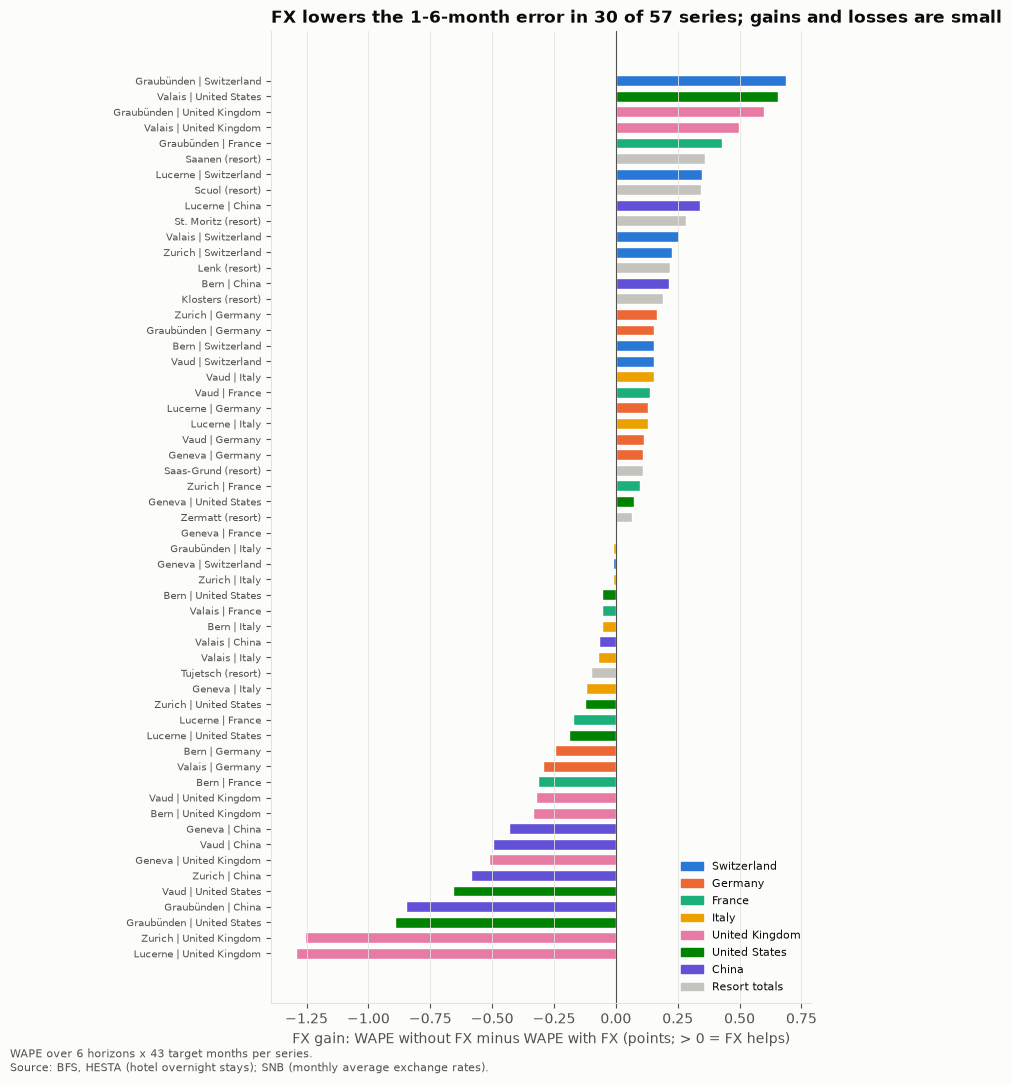

In [10]:
ps = per_series.sort_values("fx_gain")
colors = [GREY if m == "Resort totals" else ORIGIN_COLORS[m] for m in ps["market"]]
fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(ps["series_id"], ps["fx_gain"], color=colors, height=0.7, edgecolor="white", linewidth=1)
ax.axvline(0, color=INK_SOFT, lw=0.8)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("FX gain: WAPE without FX minus WAPE with FX (points; > 0 = FX helps)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREY if m == "Resort totals" else ORIGIN_COLORS[m], label=m)
                   for m in MARKET_ORDER], loc="lower right", fontsize=8)
ax.set_title(f"FX lowers the 1-6-month error in {n_gain} of 57 series; gains and losses are small",
             loc="left", fontsize=12)
add_source(fig, SOURCE_BFS_SNB + ".", "WAPE over 6 horizons x 43 target months per series.")
fig.subplots_adjust(left=0.3, bottom=0.07)
save(fig, "12_fx_gain_by_series")

## Limitations

- **Short test period.** 43 post-covid target months (Jan 2023 - Jul 2026), i.e. few origins and only one notable FX episode (the franc's 2022-2024 strength). Small differences between models, especially per series, can be noise; no significance test is run.
- **Results use scikit-learn's HistGradientBoostingRegressor**, not LightGBM, which could not be installed on this machine; it has no row subsampling, so results may differ slightly from LightGBM.
- **Hotels only** (HESTA). Resort totals are the sum of 7 tracked markets, with suppressed small-market months counted as 0.
- **FX choices from notebook 02** (lag h, one symmetric feature) were selected on the full sample; this backtest is their first out-of-sample test, not a re-selection.
- **Point forecasts only**: no prediction intervals yet (needed for staffing decisions).
- **Out of scope**: overbooking and nightly pricing need daily, hotel-level data (cancellations, no-shows, capacity).

## Summary check

Every number in the summary at the top must match the results above.

In [11]:
f1 = lambda x: f"{x:.1f}"
f2 = lambda x: f"{x:+.2f}"
row = lambda r: (f1(r.naive), f1(r.gb_no_fx), f1(r.gb_fx), f2(r.fx_gain), int(r.fx_helps_in_h))
by_h1 = by_h[(by_h["months"] == "all") & (by_h["h"] == 1)].iloc[0]
by_h6 = by_h[(by_h["months"] == "all") & (by_h["h"] == 6)].iloc[0]
o = overall.loc["all"]; p = overall.loc["peak season"]
checks = {
    "overall naive/no FX/FX/gain": (f1(o.naive), f1(o.gb_no_fx), f1(o.gb_fx), f2(o.fx_gain)) == ('8.7', '8.3', '8.2', '+0.16'),
    "peak naive/no FX/FX": (f1(p.naive), f1(p.gb_no_fx), f1(p.gb_fx)) == ('8.5', '8.4', '8.1'),
    "h=1 model vs naive": (f1(by_h1.gb_no_fx), f1(by_h1.naive)) == ('7.4', '8.7'),
    "h=6 naive/no FX/FX": (f1(by_h6.naive), f1(by_h6.gb_no_fx), f1(by_h6.gb_fx)) == ('8.7', '9.0', '8.6'),
    "market Switzerland": row(by_market.loc["Switzerland"]) == ('6.2', '6.6', '6.3', '+0.31', 6),
    "market Germany": row(by_market.loc["Germany"]) == ('9.6', '9.9', '9.9', '+0.03', 2),
    "market France": row(by_market.loc["France"]) == ('8.0', '8.1', '8.1', '+0.02', 4),
    "market Italy": row(by_market.loc["Italy"]) == ('11.7', '12.0', '12.0', '-0.01', 3),
    "market United Kingdom": row(by_market.loc["United Kingdom"]) == ('13.7', '12.0', '12.3', '-0.37', 1),
    "market United States": row(by_market.loc["United States"]) == ('13.7', '9.4', '9.4', '-0.07', 3),
    "market China": row(by_market.loc["China"]) == ('34.2', '27.5', '27.6', '-0.14', 3),
    "market Resort totals": row(by_market.loc["Resort totals"]) == ('8.0', '8.4', '8.2', '+0.18', 4),
    "series where FX helps": n_gain == 30,
    "series where model beats naive": model_beats_naive == 24,
    "naive beats model w/o FX for CH, DE, FR, IT, resorts": all(by_market.loc[m, "gb_no_fx"] > by_market.loc[m, "naive"] for m in ["Switzerland", "Germany", "France", "Italy", "Resort totals"]),
    "model beats naive for US, China, UK": all(by_market.loc[m, "gb_no_fx"] < by_market.loc[m, "naive"] for m in ["United States", "China", "United Kingdom"]),
    "largest market gain is Swiss (FX feature 0)": by_market["fx_gain"].idxmax() == "Switzerland",
}

for name, ok in checks.items():
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
assert checks and all(checks.values()), "the summary at the top no longer matches the results"
con.close()
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("1[0-2]_*.png")))

OK   overall naive/no FX/FX/gain
OK   peak naive/no FX/FX
OK   h=1 model vs naive
OK   h=6 naive/no FX/FX
OK   market Switzerland
OK   market Germany
OK   market France
OK   market Italy
OK   market United Kingdom
OK   market United States
OK   market China
OK   market Resort totals
OK   series where FX helps
OK   series where model beats naive
OK   naive beats model w/o FX for CH, DE, FR, IT, resorts
OK   model beats naive for US, China, UK
OK   largest market gain is Swiss (FX feature 0)
['10_wape_by_horizon.png', '11_actual_vs_forecast_h6.png', '12_fx_gain_by_series.png']
